# Loading

In [1]:
import pandas as pd

boundaries = pd.read_csv("Boundaries_(2023-2024).csv")

import matplotlib.pyplot as plt
import geopandas as gpd
precinct_gdf = gpd.read_file('Precinct.geojson')


# Build and Merge Tract

In [2]:
# Dissolving up to ward level because turnout and boundaries data are only meaningful at that scale
import geopandas as gpd
from shapely import wkt

boundaries['geometry'] = boundaries['the_geom'].apply(wkt.loads) # Converts WKT strings to polygons
precincts_gdf = gpd.GeoDataFrame(boundaries, geometry='geometry', crs='EPSG:4326') # Creates a GeoDataFrame

wards_gdf = precincts_gdf.dissolve(by='Ward', as_index=False) #Mergers precinnts into wards 
wards_gdf = wards_gdf[['Ward', 'geometry']] # Trim down to just the columns needed

print(wards_gdf.shape)

(50, 2)


In [3]:
wards_gdf.to_csv('wards_shapes.csv', index=False)

In [4]:
df_muslim = pd.read_csv('df_muslim_clean.csv')
df_citizen = pd.read_csv('df_citizen_clean.csv')

In [5]:
tracts_gdf = gpd.read_file('tl_2023_17_tract.shp') # Buids tract geoframe from shapefile
print(tracts_gdf.shape)
print(tracts_gdf.columns.tolist())
print(tracts_gdf['COUNTYFP'].unique())

(3265, 14)
['STATEFP', 'COUNTYFP', 'TRACTCE', 'GEOID', 'GEOIDFQ', 'NAME', 'NAMELSAD', 'MTFCC', 'FUNCSTAT', 'ALAND', 'AWATER', 'INTPTLAT', 'INTPTLON', 'geometry']
['161' '019' '199' '091' '119' '111' '189' '089' '193' '029' '143' '163'
 '197' '157' '133' '097' '115' '035' '043' '031' '073' '045' '127' '093'
 '051' '109' '183' '181' '187' '129' '117' '141' '037' '015' '123' '081'
 '201' '011' '135' '065' '195' '085' '113' '077' '023' '021' '061' '001'
 '083' '041' '153' '167' '057' '121' '095' '107' '047' '101' '173' '149'
 '013' '067' '079' '099' '139' '055' '009' '179' '155' '169' '147' '027'
 '103' '005' '165' '105' '145' '003' '063' '007' '069' '191' '137' '087'
 '185' '159' '049' '075' '059' '053' '071' '177' '017' '033' '025' '131'
 '125' '151' '203' '039' '175' '171']


In [6]:
print(tracts_gdf['GEOID'].head(3))
print(df_muslim['GEO_ID'].head(3))

0    17161022800
1    17161022900
2    17161023000
Name: GEOID, dtype: object
0    17031010100
1    17031010201
2    17031010202
Name: GEO_ID, dtype: int64


In [7]:
# Casting to str because merge keys silently fail to match across dtypes 
tracts_gdf['GEOID'] = tracts_gdf['GEOID'].astype(str)
df_muslim['GEO_ID'] = df_muslim['GEO_ID'].astype(str)
df_citizen['GEO_ID'] = df_citizen['GEO_ID'].astype(str)

# Inner join on muslim data to set the base rows, left join citizen data so we don't drop rows if it's missing
tracts_gdf = tracts_gdf.merge(df_muslim, left_on='GEOID', right_on='GEO_ID', how='inner')
tracts_gdf = tracts_gdf.merge(df_citizen, on='GEO_ID', how='left')

print(tracts_gdf.shape)
print(tracts_gdf.columns.tolist())




(1332, 38)
['STATEFP', 'COUNTYFP', 'TRACTCE', 'GEOID', 'GEOIDFQ', 'NAME', 'NAMELSAD', 'MTFCC', 'FUNCSTAT', 'ALAND', 'AWATER', 'INTPTLAT', 'INTPTLON', 'geometry', 'GEO_ID', 'B05006_057E', 'B05006_058E', 'B05006_064E', 'B05006_061E', 'B05006_066E', 'B05006_071E', 'B05006_081E', 'B05006_083E', 'B05006_085E', 'B05006_086E', 'B05006_088E', 'B05006_089E', 'B05006_090E', 'B05006_092E', 'B05006_100E', 'B05006_111E', 'B05006_112E', 'B05006_113E', 'B05006_114E', 'B05006_125E', 'muslim_foreign_born', 'naturalized_citizens', 'non_citizens']


In [8]:
print(tracts_gdf['muslim_foreign_born'].sum())      
print(tracts_gdf['naturalized_citizens'].sum())     
print(tracts_gdf['non_citizens'].sum())            

62338
583778
514319


# Spatial Join for Wards

In [9]:
# Using centroid as a single representative point per tract for the spatial join
tract_centroids_latlon = tracts_gdf.copy()
tract_centroids_latlon['geometry'] = tract_centroids_latlon.geometry.centroid

tract_to_ward_latlon = gpd.sjoin(tract_centroids_latlon, wards_gdf, how='left', predicate='within')

print(tract_to_ward_latlon.crs)       
print(wards_gdf.crs)                  
print(tract_to_ward_latlon['Ward'].isna().sum())

EPSG:4269
EPSG:4326
554


C:\Users\abdif\AppData\Local\Temp\ipykernel_32756\859268126.py:3: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  tract_centroids_latlon['geometry'] = tract_centroids_latlon.geometry.centroid
C:\Users\abdif\AppData\Local\Temp\ipykernel_32756\859268126.py:5: UserWarning: CRS mismatch between the CRS of left geometries and the CRS of right geometries.
Use `to_crs()` to reproject one of the input geometries to match the CRS of the other.

Left CRS: EPSG:4269
Right CRS: EPSG:4326

  tract_to_ward_latlon = gpd.sjoin(tract_centroids_latlon, wards_gdf, how='left', predicate='within')


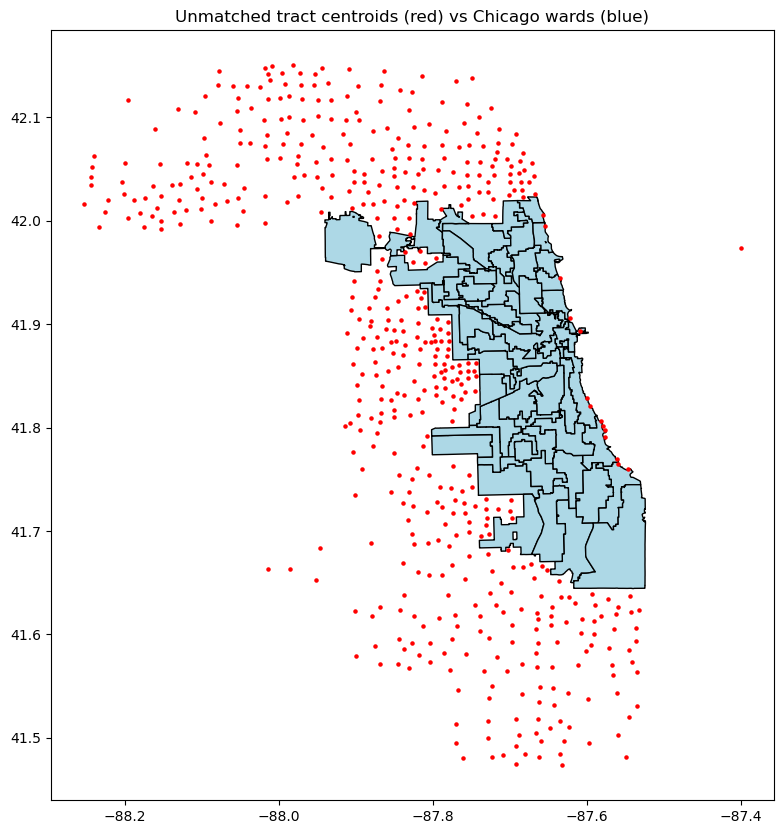

In [10]:
fig, ax = plt.subplots(figsize=(10,10))
wards_gdf.plot(ax=ax, color='lightblue', edgecolor='black')
tract_to_ward_latlon[tract_to_ward_latlon['Ward'].isna()].plot(ax=ax, color='red', markersize=5)
plt.title('Unmatched tract centroids (red) vs Chicago wards (blue)')
plt.show()


# Spatial Join for Townships

In [11]:
townships_gdf = precinct_gdf.dissolve(by='Township_Name', as_index=False)
townships_gdf = townships_gdf[['Township_Name', 'geometry']]

print(townships_gdf.shape)   
print(townships_gdf.crs)     

(30, 2)
EPSG:4326


In [12]:
townships_gdf.to_csv('townships_shapes.csv', index=False)

In [13]:
# Pull out just the suburban tracts: the ones that didn't fall inside any Chicago ward
suburban_tracts = tract_to_ward_latlon[tract_to_ward_latlon['Ward'].isna()].copy()

# Drop leftover join columns from the earlier ward spatial join, so they don't collide with this one
suburban_tracts = suburban_tracts.drop(columns=['index_right', 'Ward'], errors='ignore')

tract_to_township = gpd.sjoin(suburban_tracts, townships_gdf, how='left', predicate='within')

print(tract_to_township.shape)                         
print(tract_to_township['Township_Name'].isna().sum())   

(554, 40)
18


C:\Users\abdif\AppData\Local\Temp\ipykernel_32756\3842534177.py:7: UserWarning: CRS mismatch between the CRS of left geometries and the CRS of right geometries.
Use `to_crs()` to reproject one of the input geometries to match the CRS of the other.

Left CRS: EPSG:4269
Right CRS: EPSG:4326

  tract_to_township = gpd.sjoin(suburban_tracts, townships_gdf, how='left', predicate='within')


In [14]:
unmatched_township = tract_to_township[tract_to_township['Township_Name'].isna()]

print(unmatched_township.shape)
print(unmatched_township['muslim_foreign_born'].sum())
print(unmatched_township['naturalized_citizens'].sum())
print(unmatched_township[['GEOID']])

(18, 40)
749
3928
            GEOID
101   17031809401
118   17031836400
122   17031061902
124   17031030103
127   17031081202
157   17031430102
305   17031431400
384   17031390700
429   17031410100
469   17031410900
470   17031411000
524   17031801200
626   17031010400
681   17031800400
721   17031990000
1040  17031836500
1206  17031081402
1296  17031430700


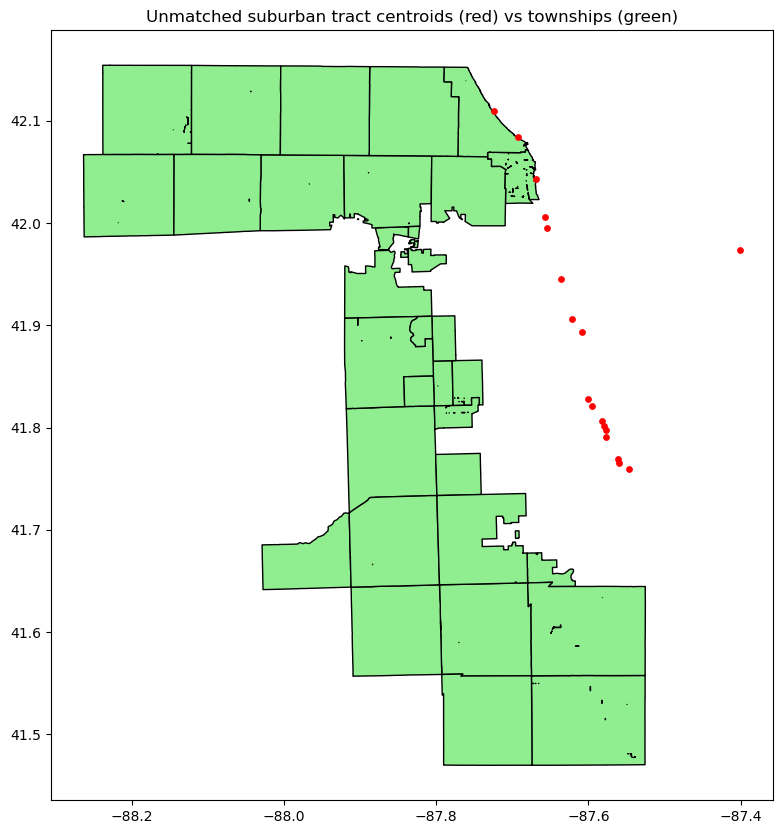

In [15]:
# Checking how much population is at stake in the unmatched tracts before deciding whether to fix or exclude

fig, ax = plt.subplots(figsize=(10,10))
townships_gdf.plot(ax=ax, color='lightgreen', edgecolor='black')
unmatched_township.plot(ax=ax, color='red', markersize=15)
plt.title('Unmatched suburban tract centroids (red) vs townships (green)')
plt.show()

# Missing Tracts

In [16]:
# Get the GEOIDs of the 18 tracts that didn't match
unmatched_ids = unmatched_township['GEOID'].tolist()

# Rebuild those specific rows using representative_point() instead of centroid 
fix_rows = suburban_tracts[suburban_tracts['GEOID'].isin(unmatched_ids)].copy()
fix_rows['geometry'] = tracts_gdf[tracts_gdf['GEOID'].isin(unmatched_ids)].geometry.representative_point().values

# Re-run the spatial join for just these 18 rows
fix_joined = gpd.sjoin(fix_rows, townships_gdf, how='left', predicate='within')
print(fix_joined['Township_Name'].isna().sum())  

17


C:\Users\abdif\AppData\Local\Temp\ipykernel_32756\2569388287.py:9: UserWarning: CRS mismatch between the CRS of left geometries and the CRS of right geometries.
Use `to_crs()` to reproject one of the input geometries to match the CRS of the other.

Left CRS: EPSG:4269
Right CRS: EPSG:4326

  fix_joined = gpd.sjoin(fix_rows, townships_gdf, how='left', predicate='within')


In [17]:
still_unmatched = fix_joined[fix_joined['Township_Name'].isna()]
print(still_unmatched[['GEOID']])
print(tracts_gdf[tracts_gdf['GEOID'] == still_unmatched['GEOID'].iloc[0]].geometry.iloc[0])

            GEOID
118   17031836400
122   17031061902
124   17031030103
127   17031081202
157   17031430102
305   17031431400
384   17031390700
429   17031410100
469   17031410900
470   17031411000
524   17031801200
626   17031010400
681   17031800400
721   17031990000
1040  17031836500
1206  17031081402
1296  17031430700
POLYGON ((-87.606859 41.823129, -87.606808 41.823147, -87.606655 41.823201, -87.606604 41.823219, -87.606515 41.82337, -87.606502 41.82335, -87.606466 41.82329, -87.606454 41.823271, -87.606155 41.823375, -87.60575 41.823517, -87.605634 41.823558, -87.605256 41.823681, -87.604955 41.823779, -87.604862 41.823809, -87.604658 41.823883, -87.604532 41.82393, -87.604335 41.823999, -87.60419 41.824051, -87.604015 41.82411, -87.603767 41.824193, -87.603469 41.824294, -87.603225 41.824376, -87.602548 41.824606, -87.602495 41.824628, -87.60247 41.824639, -87.602258 41.824728, -87.602246 41.824733, -87.60221 41.824747, -87.602199 41.824753, -87.601983 41.824843, -87.601945 41.8

In [18]:
still_unmatched_geoms = fix_joined[fix_joined['Township_Name'].isna()]

for idx, row in still_unmatched_geoms.iterrows():
    point = row['geometry']
    distances = townships_gdf.geometry.distance(point)
    nearest_dist = distances.min()
    nearest_township = townships_gdf.loc[distances.idxmin(), 'Township_Name']
    print(row['GEOID'], nearest_township, round(nearest_dist, 6))

17031836400 WORTH 0.121993
17031061902 EVANSTON 0.083076
17031030103 EVANSTON 0.029277
17031081202 CICERO 0.124155
17031430102 CALUMET 0.124144
17031431400 THORNTON 0.114041
17031390700 WORTH 0.122486
17031410100 WORTH 0.122296
17031410900 WORTH 0.122645
17031411000 WORTH 0.118874
17031801200 NEW TRIER 0.003149
17031010400 EVANSTON 0.018865
17031800400 NEW TRIER 0.001888
17031990000 EVANSTON 0.276911
17031836500 WORTH 0.123583
17031081402 CICERO 0.129016
17031430700 CALUMET 0.118095


C:\Users\abdif\AppData\Local\Temp\ipykernel_32756\2852008367.py:5: UserWarning: Geometry is in a geographic CRS. Results from 'distance' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  distances = townships_gdf.geometry.distance(point)
C:\Users\abdif\AppData\Local\Temp\ipykernel_32756\2852008367.py:5: UserWarning: Geometry is in a geographic CRS. Results from 'distance' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  distances = townships_gdf.geometry.distance(point)
C:\Users\abdif\AppData\Local\Temp\ipykernel_32756\2852008367.py:5: UserWarning: Geometry is in a geographic CRS. Results from 'distance' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  distances = townships_gdf.geometry.distance(point)
C:\Users\abdif\AppData\Local\Temp\ipykernel_32756\2852008367.py:5: UserWarning: Geome

In [19]:
print(townships_gdf.geometry.is_valid.value_counts())
print(townships_gdf.geometry.is_empty.sum())

True    30
Name: count, dtype: int64
0


In [20]:
# Ruling out a tiny boundary seam vs a real coverage gap before choosing a fix

suburban_union = townships_gdf.union_all()

for idx, row in still_unmatched_geoms.iterrows():
    point = row['geometry']
    is_inside = point.within(suburban_union)
    dist_to_union = suburban_union.distance(point)
    print(row['GEOID'], "inside overall shape:", is_inside, "| distance if outside:", round(dist_to_union, 6))

17031836400 inside overall shape: False | distance if outside: 0.121993
17031061902 inside overall shape: False | distance if outside: 0.083076
17031030103 inside overall shape: False | distance if outside: 0.029277
17031081202 inside overall shape: False | distance if outside: 0.124155
17031430102 inside overall shape: False | distance if outside: 0.124144
17031431400 inside overall shape: False | distance if outside: 0.114041
17031390700 inside overall shape: False | distance if outside: 0.122486
17031410100 inside overall shape: False | distance if outside: 0.122296
17031410900 inside overall shape: False | distance if outside: 0.122645
17031411000 inside overall shape: False | distance if outside: 0.118874
17031801200 inside overall shape: False | distance if outside: 0.003149
17031010400 inside overall shape: False | distance if outside: 0.018865
17031800400 inside overall shape: False | distance if outside: 0.001888
17031990000 inside overall shape: False | distance if outside: 0

In [21]:
# Checking whether these tracts have real population before deciding to fix rather than exclude

check_pop = df_muslim[df_muslim['GEO_ID'].isin(
    still_unmatched_geoms['GEO_ID'].tolist()
)][['GEO_ID', 'muslim_foreign_born']]
print(check_pop)

           GEO_ID  muslim_foreign_born
4     17031010400                   14
27    17031030103                   81
89    17031061902                   34
133   17031081202                   69
136   17031081402                  154
420   17031390700                  112
425   17031410100                   20
431   17031410900                    8
432   17031411000                  115
445   17031430102                    0
451   17031430700                    0
457   17031431400                  106
696   17031800400                    0
704   17031801200                   33
1267  17031836400                    0
1268  17031836500                    0
1331  17031990000                    0


In [22]:
# Fix the 17 tracts in a real township-coverage gap, using nearest-neighbor assignment
to_fix = gpd.GeoDataFrame(
    still_unmatched_geoms.drop(columns=['Township_Name', 'index_right'], errors='ignore'),
    geometry='geometry', crs=townships_gdf.crs
)

nearest_fix = gpd.sjoin_nearest(to_fix, townships_gdf, how='left')
nearest_lookup = nearest_fix.set_index('GEOID')['Township_Name']

print(f"Tracts resolved via nearest-township: {len(nearest_lookup)}")   
print(nearest_fix[['GEOID', 'Township_Name']])

# Merge this fix, plus the 1 tract already resolved earlier via representative_point(), into tract_to_township
fix_lookup = fix_joined.dropna(subset=['Township_Name']).set_index('GEOID')['Township_Name']
all_fixes = pd.concat([fix_lookup, nearest_lookup])

tract_to_township.loc[tract_to_township['GEOID'].isin(all_fixes.index), 'Township_Name'] = \
    tract_to_township['GEOID'].map(all_fixes)

print(tract_to_township['Township_Name'].isna().sum())   

Tracts resolved via nearest-township: 17
            GEOID Township_Name
118   17031836400         WORTH
122   17031061902      EVANSTON
124   17031030103      EVANSTON
127   17031081202        CICERO
157   17031430102       CALUMET
305   17031431400      THORNTON
384   17031390700         WORTH
429   17031410100         WORTH
469   17031410900         WORTH
470   17031411000         WORTH
524   17031801200     NEW TRIER
626   17031010400      EVANSTON
681   17031800400     NEW TRIER
721   17031990000      EVANSTON
1040  17031836500         WORTH
1206  17031081402        CICERO
1296  17031430700       CALUMET
0


c:\Users\abdif\anaconda3\Lib\site-packages\geopandas\array.py:411: UserWarning: Geometry is in a geographic CRS. Results from 'sjoin_nearest' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  warnings.warn(


In [23]:
ward_pop = tract_to_ward_latlon[tract_to_ward_latlon['Ward'].notna()].groupby('Ward')[['muslim_foreign_born', 'naturalized_citizens', 'non_citizens']].sum().reset_index()

print(ward_pop.shape)   
print(ward_pop.head(10))

(50, 4)
   Ward  muslim_foreign_born  naturalized_citizens  non_citizens
0   1.0                  323                  3624          3085
1   2.0                  405                  3108          3561
2   3.0                  884                  3050          2794
3   4.0                  890                  3535          5637
4   5.0                  353                  1180          2920
5   6.0                   41                   646           447
6   7.0                   22                  1502          1057
7   8.0                   91                  1140          1009
8   9.0                    0                   437           611
9  10.0                  171                  4585          6178


In [24]:
township_pop = tract_to_township.groupby('Township_Name')[['muslim_foreign_born', 'naturalized_citizens', 'non_citizens']].sum().reset_index()

print(township_pop.shape)   
print(township_pop['muslim_foreign_born'].sum())  

(30, 4)
39889


# Manual Checks

In [25]:
maine = tract_to_township[tract_to_township['Township_Name'] == 'MAINE'].iloc[0]
niles = tract_to_township[tract_to_township['Township_Name'] == 'NILES'].iloc[0]
ward40 = tract_to_ward_latlon[tract_to_ward_latlon['Ward'] == 40.0].iloc[0]
ward12 = tract_to_ward_latlon[tract_to_ward_latlon['Ward'] == 12.0].iloc[0]

In [26]:
for name, row in [('Maine', maine), ('Niles', niles), ('Ward 40', ward40), ('Ward 12', ward12)]:
    print(f"{name}: GEOID={row['GEOID']}, muslim_foreign_born={row['muslim_foreign_born']}, naturalized_citizens={row['naturalized_citizens']}, centroid=({row.geometry.centroid.y}, {row.geometry.centroid.x})")

Maine: GEOID=17031770602, muslim_foreign_born=102, naturalized_citizens=914, centroid=(42.01239430331476, -87.90448915781971)
Niles: GEOID=17031807100, muslim_foreign_born=78, naturalized_citizens=562, centroid=(42.044453334438806, -87.72107860744505)
Ward 40: GEOID=17031040401, muslim_foreign_born=12, naturalized_citizens=398, centroid=(41.97206673735019, -87.68608162783082)
Ward 12: GEOID=17031610300, muslim_foreign_born=0, naturalized_citizens=353, centroid=(41.816178003215754, -87.67510211828254)


In [27]:
for geoid in still_unmatched_geoms['GEOID']:
    tract_row = tracts_gdf[tracts_gdf['GEOID'] == geoid].iloc[0]
    print(f"Unmatched tract {geoid}: muslim_foreign_born={tract_row['muslim_foreign_born']}, naturalized_citizens={tract_row['naturalized_citizens']}, centroid=({tract_row.geometry.centroid.y}, {tract_row.geometry.centroid.x})")

Unmatched tract 17031836400: muslim_foreign_born=0, naturalized_citizens=215, centroid=(41.82117510558148, -87.59583251114243)
Unmatched tract 17031061902: muslim_foreign_born=34, naturalized_citizens=371, centroid=(41.9449289313319, -87.63570838532806)
Unmatched tract 17031030103: muslim_foreign_born=81, naturalized_citizens=210, centroid=(41.99538041996234, -87.65469538012857)
Unmatched tract 17031081202: muslim_foreign_born=69, naturalized_citizens=300, centroid=(41.90614082818039, -87.6218049188613)
Unmatched tract 17031430102: muslim_foreign_born=0, naturalized_citizens=71, centroid=(41.76939065153051, -87.56161548390273)
Unmatched tract 17031431400: muslim_foreign_born=106, naturalized_citizens=239, centroid=(41.75967032748728, -87.54722714221528)
Unmatched tract 17031390700: muslim_foreign_born=112, naturalized_citizens=260, centroid=(41.80638357606706, -87.5825384550627)
Unmatched tract 17031410100: muslim_foreign_born=20, naturalized_citizens=141, centroid=(41.80150187741049, 

In [28]:
for geoid in ['17031770602','17031807100','17031040401','17031610300']:
    raw_muslim = df_muslim[df_muslim['GEO_ID'] == geoid]['muslim_foreign_born'].values
    raw_citizen = df_citizen[df_citizen['GEO_ID'] == geoid]['naturalized_citizens'].values
    print(f"{geoid}: raw_muslim={raw_muslim}, raw_citizen={raw_citizen}")


17031770602: raw_muslim=[102], raw_citizen=[914]
17031807100: raw_muslim=[78], raw_citizen=[562]
17031040401: raw_muslim=[12], raw_citizen=[398]
17031610300: raw_muslim=[0], raw_citizen=[353]


In [29]:
maine_manual = tract_to_township[tract_to_township['Township_Name']=='MAINE']['muslim_foreign_born'].sum()
maine_pipeline = township_pop[township_pop['Township_Name']=='MAINE']['muslim_foreign_born'].values[0]
print(f"Maine: manual={maine_manual}, pipeline={maine_pipeline}, match={maine_manual == maine_pipeline}")

niles_manual = tract_to_township[tract_to_township['Township_Name']=='NILES']['muslim_foreign_born'].sum()
niles_pipeline = township_pop[township_pop['Township_Name']=='NILES']['muslim_foreign_born'].values[0]
print(f"Niles: manual={niles_manual}, pipeline={niles_pipeline}, match={niles_manual == niles_pipeline}")

ward40_manual = tract_to_ward_latlon[tract_to_ward_latlon['Ward'] == 40.0]['muslim_foreign_born'].sum()
ward40_pipeline = ward_pop[ward_pop['Ward'] == 40.0]['muslim_foreign_born'].values[0]
print(f"Ward 40: manual={ward40_manual}, pipeline={ward40_pipeline}, match={ward40_manual == ward40_pipeline}")

ward12_manual = tract_to_ward_latlon[tract_to_ward_latlon['Ward'] == 12.0]['muslim_foreign_born'].sum()
ward12_pipeline = ward_pop[ward_pop['Ward'] == 12.0]['muslim_foreign_born'].values[0]
print(f"Ward 12: manual={ward12_manual}, pipeline={ward12_pipeline}, match={ward12_manual == ward12_pipeline}")

Maine: manual=5439, pipeline=5439, match=True
Niles: manual=9307, pipeline=9307, match=True
Ward 40: manual=2390, pipeline=2390, match=True
Ward 12: manual=345, pipeline=345, match=True


# Export

In [30]:
ward_pop.to_csv('ward_pop.csv', index=False)
township_pop.to_csv('township_pop.csv', index=False)